# Figure S1 - piControl extreme temperature frequencies

In [1]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
from collections import defaultdict
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from matplotlib.colors import ListedColormap, BoundaryNorm
import warnings
warnings.filterwarnings('ignore')

from cdrmip_extremes import configs, extremes, utils, pipeline, plotting, stats
from cdrmip_extremes.extremes_pipeline import ExtremesPipeline
from cdrmip_extremes.configs import colour_dict

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [3]:
config = pipeline.PipelineConfig(
    experiments=[
        pipeline.ExperimentConfig(
            experiment_id='1pctCO2-cdr', table_id='Amon', variable_id='tas',
            anomaly_reference='picontrol',grid_label=None,
            crossing_gwls=[1.5, 2.0, 3.0], overshoot=True,
            gwl_match_period=(320, 340),
            rolling_window=21,
        ),
    ],
    realign_years_overrides={'1pctCO2': (0, 140)}
)

In [4]:
config = pipeline.CDRMIPPipeline(config)

In [5]:
pipe = config.run()

=== Loading 1pctCO2-cdr ===
Searching for files matching: {'experiment_id': '1pctCO2-cdr', 'table_id': 'Amon', 'variable_id': 'tas', 'grid_label': None, 'member_id': None}
Loading ACCESS-ESM1-5 / r1i1p1f1
  0241-01-16 12:00:00 -> 1000-12-16 12:00:00
Loading CESM2 / r1i1p1f1
  0001-01-15 12:00:00 -> 0200-12-15 12:00:00
Loading CNRM-ESM2-1 / r1i1p1f2
  1990-01-16 12:00:00 -> 2189-12-16 12:00:00
Loading CanESM5 / r1i1p2f1
  1991-01-16 12:00:00 -> 2290-12-16 12:00:00
Loading GFDL-ESM4 / r1i1p1f1
  0141-01-16 12:00:00 -> 0340-12-16 12:00:00
Loading MIROC-ES2L / r1i1p1f2
  1989-01-16 12:00:00 -> 2490-12-16 12:00:00
Loading NorESM2-LM / r1i1p1f1
  0141-01-16 12:00:00 -> 0399-12-16 12:00:00
Loading UKESM1-0-LL / r1i1p1f2
  1990-01-16 00:00:00 -> 2639-12-16 00:00:00
Searching for ACCESS-ESM1-5 1pctCO2-cdr r1i1p1f1 parent
Loading ACCESS-ESM1-5 1pctCO2 r1i1p1f1
Concatenating 1pctCO2-cdr -> 1pctCO2 [ACCESS-ESM1-5] via realign_years=(0, 140)
Concatenating via realign_years=(0, 140) (parent relabele

## Calculate Exceedances for regridded_piControl

In [6]:
ext = ExtremesPipeline(
    regridded_picontrol=pipe.regridded_picontrol,
    regridded_concat=pipe.regridded_concat,
    crossing_years=pipe.crossing_years,
    gwl_matching=pipe.gwl_matching,
    gwl_window=21
)    

In [7]:
ext.compute_extreme_months().compute_thresholds()

In [8]:
exceedances = defaultdict(dict)
for model, member_dt in ext.regridded_picontrol.items():
    print(model)
    member_exceedances = {'heat':[],'cold':[]}
    for member, ds in member_dt.items():
        print(member)
        ext_months = ext.extreme_months[model][member]
        ext_month_tas = extremes.select_extreme_month(ds,ext_months)
        for ext_type in ['heat','cold']:
            thresholds = ext.thresholds[model][member][ext_type]
            exceedance_ds = extremes.calculate_exceedances(
                ext_month_tas,
                thresholds,
                ext_type=ext_type
            )
            member_exceedances[ext_type].append(exceedance_ds)
    for ext_type in ['heat','cold']:
        exceedances[model][ext_type] = xr.concat(
            member_exceedances[ext_type],
            dim='member'
        ).median(dim='member')

exceedances = dict(exceedances)

ACCESS-ESM1-5
r1i1p1f1
CESM2
r1i1p1f1
CNRM-ESM2-1
r1i1p1f2
CanESM5
r1i1p2f1
GFDL-ESM4
r1i1p1f1
MIROC-ES2L
r1i1p1f2
NorESM2-LM
r1i1p1f1
UKESM1-0-LL
r1i1p1f2


In [9]:
median = {
    ext_type: xr.concat(
        [exceedances[model][ext_type] for model in exceedances.keys()],
        dim='model',
        compat='override',
        coords='minimal'
    ).median(dim='model') for ext_type in ['heat','cold']
}

In [10]:
exceedances['Multi-Model Median'] = median

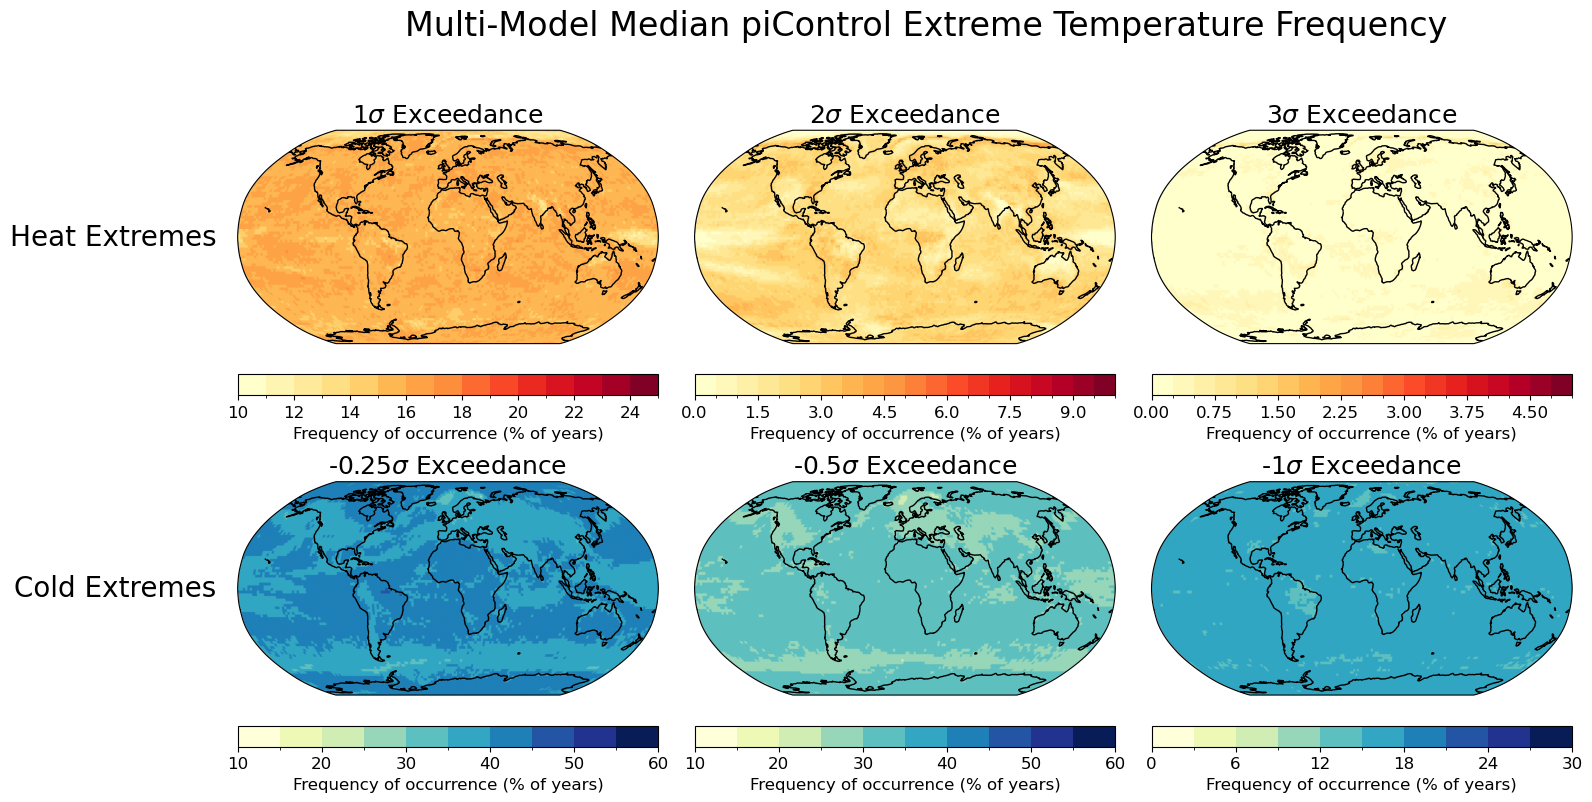

In [11]:
# define symbols for threhsolds for title
heat_symbs = {'sigma1':'1$\sigma$',
              'sigma2':'2$\sigma$',
              'sigma3':'3$\sigma$'
            }
cold_symbs = {'sigma1':'-0.25$\sigma$',
              'sigma2':'-0.5$\sigma$',
              'sigma3':'-1$\sigma$'
            }
thresholds = ['sigma1','sigma2','sigma3']
to_plot = {
    'heat':{
        threshold: exceedances['Multi-Model Median']['heat'][threshold] for threshold in thresholds
    },
    'cold':{
        threshold: exceedances['Multi-Model Median']['cold'][threshold] for threshold in thresholds
    },       
}

levels_dict = {
    'heat': {
        'sigma1':BoundaryNorm(np.linspace(10,25,16), ncolors=plt.cm.YlOrRd.N, clip=True),
        'sigma2':BoundaryNorm(np.linspace(0,10,21), ncolors=plt.cm.YlOrRd.N, clip=True),
        'sigma3':BoundaryNorm(np.linspace(0,5,21), ncolors=plt.cm.YlOrRd.N, clip=True),
    },
    'cold': {
        'sigma1':BoundaryNorm(np.linspace(10,60,11), ncolors=plt.cm.YlOrRd.N, clip=True),
        'sigma2':BoundaryNorm(np.linspace(10,60,11), ncolors=plt.cm.YlOrRd.N, clip=True),
        'sigma3':BoundaryNorm(np.linspace(0,30,11), ncolors=plt.cm.YlOrRd.N, clip=True),
    }
}   

fig, axes = plt.subplots(2,3, subplot_kw={"projection":ccrs.Robinson()},
                     figsize=(16,8),
                     sharey=True,)

cbar_kwargs = {"fraction": 0.08, "aspect": 20,
                "label":"% Years",'orientation':'horizontal',
                'location':'bottom','pad':0.04,
              'anchor':(0.5,-4), #'extend':'both'
              }

for row_index, ext_type in enumerate(to_plot.keys()):
    if ext_type == 'heat':
        cmap='YlOrRd'
        threshold_symbs=heat_symbs
        levels = levels_dict['heat']
    else:
        cmap='YlGnBu'
        threshold_symbs=cold_symbs
        levels = levels_dict['cold']
        
    for col_index, threshold in enumerate(to_plot[ext_type].keys()):
        ax = axes[row_index,col_index]
        im = ax.imshow(to_plot[ext_type][threshold],
                       transform=ccrs.PlateCarree(),
                       cmap=cmap,
                       origin='lower',
                       extent=(0,360,-90,90),
                       norm=levels[threshold]
                      )
        ax.coastlines()
        ax.set_title(f"{threshold_symbs[threshold]} Exceedance",fontsize=18)
        
        cbar = fig.colorbar(im, ax=ax, **cbar_kwargs)
        cbar.set_label("Frequency of occurrence (% of years)", fontsize=12)
        cbar.ax.tick_params(labelsize=12)

axes[0][0].annotate('Heat Extremes',
                    xy = (-0.05,0.5),
                    xycoords="axes fraction",
                    ha='right',
                    va='center',
                    fontsize=20,
                    rotation=0
                   )
axes[1][0].annotate('Cold Extremes',
                    xy = (-0.05,0.5),
                    xycoords="axes fraction",
                    ha='right',
                    va='center',
                    fontsize=20,
                    rotation=0
                   )

fig.suptitle(f"Multi-Model Median piControl Extreme Temperature Frequency",
             fontsize=24,x=0.58,
             y=1.0
            )
fig.tight_layout()
plt.show()

In [12]:
fig.savefig(
    configs.FIG_DIR / "supplementary" / "figure_S1.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)